# 09 Explainable AI using SHAP

## Objective

The objective of this notebook is to explain the predictions generated by the final Random Forest model using SHAP (SHapley Additive exPlanations).

Unlike traditional machine learning models that only provide predictions, SHAP explains the contribution of each internship construct to the predicted employability score.

These explanations are later combined with construct scores to generate personalized employability recommendations.

In [74]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split

print("Libraries imported successfully.")
print("SHAP version:", shap.__version__)

Libraries imported successfully.
SHAP version: 0.52.0


In [75]:
PROJECT_DIR = Path.cwd().parent

DATA_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "descriptive_dataset.csv"
)

REPORT_DIR = PROJECT_DIR / "reports"
MODEL_DIR = PROJECT_DIR / "models"
FIGURE_DIR = REPORT_DIR / "figures"

for folder in [REPORT_DIR, MODEL_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset:", DATA_FILE)

Project directory: d:\internship-employability-project
Dataset: d:\internship-employability-project\data\processed\descriptive_dataset.csv


In [76]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset was not found at: {DATA_FILE}"
    )

df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully.
Rows: 1000
Columns: 29


,Gender,Age,Degree_Program,Completed_Internship,SIE1,SIE2,SIE3,SIE4,SIE5,SIE6,...,EMP4,EMP5,EMP6,EMP7,EMP8,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Employability_Score
0,Male,24–26,Engineering,Yes,4,5,4,4,5,5,...,4,4,4,5,5,4.25,5.0,4.25,4.5,4.625
1,Male,21–23,Information Technology,Yes,5,4,4,4,4,4,...,4,3,5,4,4,4.25,4.0,3.75,3.5,3.875
2,Male,21–23,Information Technology,Yes,4,5,4,4,4,3,...,4,4,5,4,3,4.25,3.5,4.00,4.0,3.875
3,Female,18–20,Engineering,Yes,4,4,4,4,4,3,...,4,4,4,4,4,4.00,3.5,3.75,3.0,4.000
4,Prefer not to say,18–20,Other,Yes,4,5,4,4,4,5,...,4,5,5,4,4,4.25,4.5,4.25,4.5,4.250


In [77]:
feature_names = [
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development",
]

target_name = "Employability_Score"

required_columns = feature_names + [target_name]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(
        f"Required columns are missing: {missing_columns}"
    )

X = df[feature_names].copy()
y = df[target_name].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Feature shape: (1000, 4)
Target shape: (1000,)


,Clear_Objectives,School_Support,Workplace_Environment,Career_Development
0,4.25,5.0,4.25,4.5
1,4.25,4.0,3.75,3.5
2,4.25,3.5,4.00,4.0
3,4.00,3.5,3.75,3.0
4,4.25,4.5,4.25,4.5


In [78]:
print("Feature missing values:")
print(X.isna().sum())

print("\nTarget missing values:", y.isna().sum())

assert X.isna().sum().sum() == 0
assert y.isna().sum() == 0

assert np.isfinite(X.to_numpy()).all()
assert np.isfinite(y.to_numpy()).all()

print("\nData validation passed.")

Feature missing values:
Clear_Objectives         0
School_Support           0
Workplace_Environment    0
Career_Development       0
dtype: int64

Target missing values: 0

Data validation passed.


In [79]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (800, 4)
Testing features: (200, 4)
Training target: (800,)
Testing target: (200,)


In [80]:
final_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)

final_rf_model.fit(X_train, y_train)

print("Final tuned Random Forest trained successfully.")

Final tuned Random Forest trained successfully.


d:\internship-employability-project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\internship-employability-project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\internship-employability-project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\internship-employability-project\.venv\Lib\sit

In [81]:
train_predictions = final_rf_model.predict(X_train)
test_predictions = final_rf_model.predict(X_test)

train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)
mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)
overfitting_gap = train_r2 - test_r2

performance = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Feature Set": "A - Internship Constructs",
    "Train R2": train_r2,
    "Test R2": test_r2,
    "MAE": mae,
    "RMSE": rmse,
    "Overfitting Gap": overfitting_gap,
}])

performance.round(4)

,Model,Feature Set,Train R2,Test R2,MAE,RMSE,Overfitting Gap
0,Tuned Random Forest,A - Internship Constructs,0.5909,0.449,0.1786,0.2952,0.1419


In [82]:
research_model_file = (
    MODEL_DIR
    / "tuned_random_forest_research_model.joblib"
)

joblib.dump(
    {
        "model": final_rf_model,
        "feature_names": feature_names,
        "target_name": target_name,
        "random_state": 42,
    },
    research_model_file,
)

print("Research model saved to:")
print(research_model_file)

Research model saved to:
d:\internship-employability-project\models\tuned_random_forest_research_model.joblib


In [83]:
explainer = shap.TreeExplainer(final_rf_model)

shap_values = explainer(X_test)

print("SHAP values calculated successfully.")
print("SHAP value shape:", shap_values.values.shape)

SHAP values calculated successfully.
SHAP value shape: (200, 4)


In [84]:
shap_reconstructed_predictions = (
    np.asarray(shap_values.base_values).reshape(-1)
    + shap_values.values.sum(axis=1)
)

model_predictions = final_rf_model.predict(X_test)

maximum_difference = np.max(
    np.abs(
        shap_reconstructed_predictions
        - model_predictions
    )
)

print(
    "Maximum SHAP reconstruction difference:",
    maximum_difference
)

assert maximum_difference < 1e-5

print("SHAP additivity validation passed.")

Maximum SHAP reconstruction difference: 3.552713678800501e-15
SHAP additivity validation passed.


In [85]:
global_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(
        shap_values.values
    ).mean(axis=0),
})

global_importance = global_importance.sort_values(
    "Mean Absolute SHAP",
    ascending=False,
).reset_index(drop=True)

global_importance["Importance Percentage"] = (
    global_importance["Mean Absolute SHAP"]
    / global_importance["Mean Absolute SHAP"].sum()
    * 100
)

global_importance.round(4)

,Feature,Mean Absolute SHAP,Importance Percentage
0,Clear_Objectives,0.0923,37.2629
1,School_Support,0.0864,34.8713
2,Workplace_Environment,0.0444,17.9363
3,Career_Development,0.0246,9.9295


In [86]:
global_importance.to_csv(
    REPORT_DIR / "SHAP_Global_Feature_Importance.csv",
    index=False,
)

print("Global SHAP importance saved.")

Global SHAP importance saved.


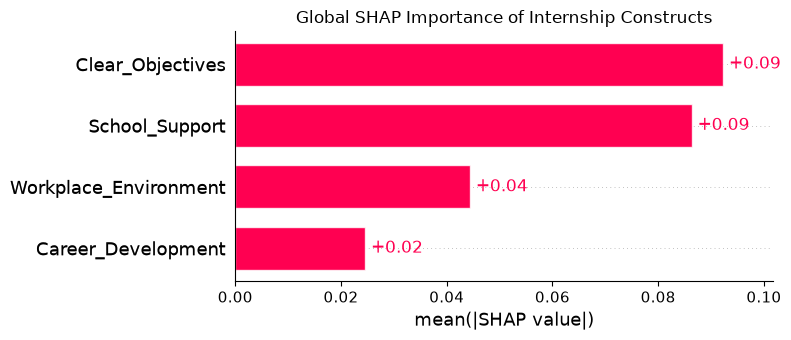

In [87]:
plt.figure()

shap.plots.bar(
    shap_values,
    max_display=4,
    show=False,
)

plt.title(
    "Global SHAP Importance of Internship Constructs"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "shap_global_bar.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

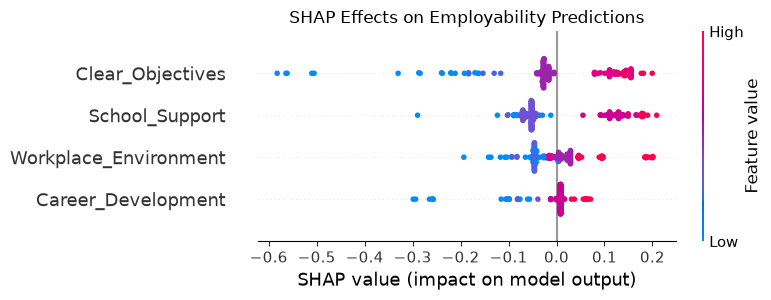

In [88]:
plt.figure()

shap.plots.beeswarm(
    shap_values,
    max_display=4,
    show=False,
)

plt.title(
    "SHAP Effects on Employability Predictions"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

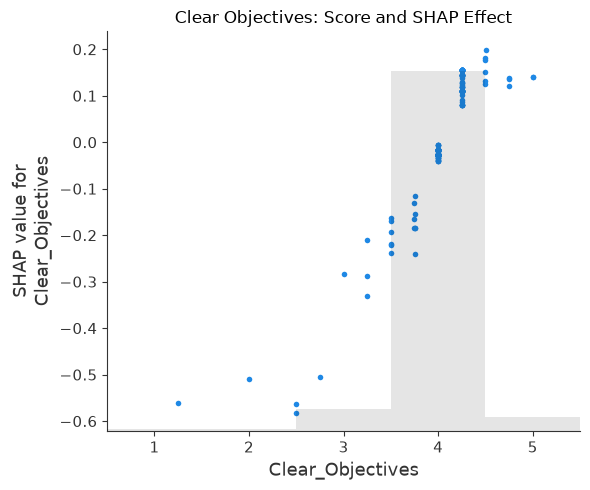

In [89]:
shap.plots.scatter(
    shap_values[:, "Clear_Objectives"],
    show=False,
)

plt.title(
    "Clear Objectives: Score and SHAP Effect"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "shap_scatter_clear_objectives.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

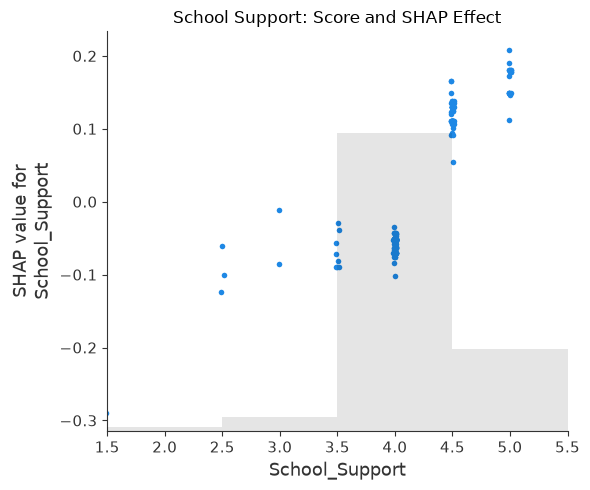

In [90]:
shap.plots.scatter(
    shap_values[:, "School_Support"],
    show=False,
)

plt.title(
    "School Support: Score and SHAP Effect"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "shap_scatter_school_support.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

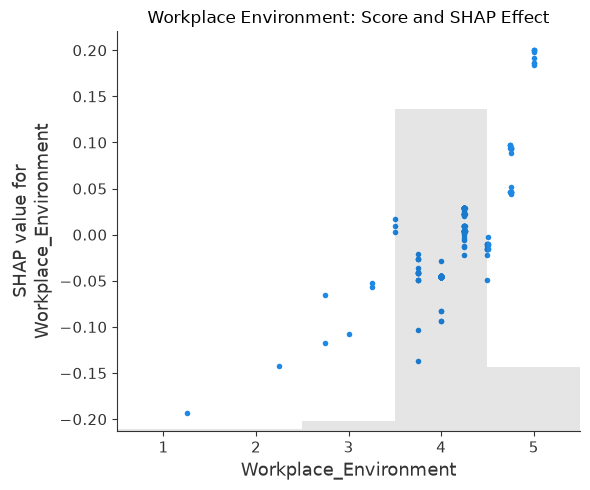

In [91]:
shap.plots.scatter(
    shap_values[:, "Workplace_Environment"],
    show=False,
)

plt.title(
    "Workplace Environment: Score and SHAP Effect"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "shap_scatter_workplace_environment.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

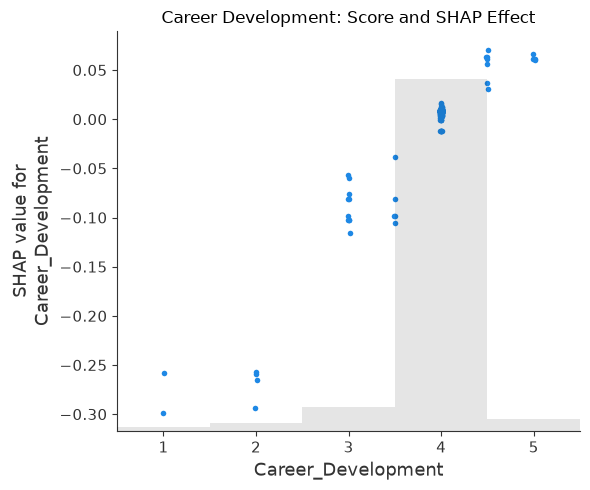

In [92]:
shap.plots.scatter(
    shap_values[:, "Career_Development"],
    show=False,
)

plt.title(
    "Career Development: Score and SHAP Effect"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "shap_scatter_career_development.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [93]:
student_position = 0

student_data = X_test.iloc[[student_position]]
student_actual = y_test.iloc[student_position]
student_prediction = final_rf_model.predict(
    student_data
)[0]

print("Student input:")
display(student_data)

print(
    "Actual Employability Score:",
    round(float(student_actual), 3)
)

print(
    "Predicted Employability Score:",
    round(float(student_prediction), 3)
)

Student input:


,Clear_Objectives,School_Support,Workplace_Environment,Career_Development
521,4.0,4.0,4.0,4.0


Actual Employability Score: 4.0
Predicted Employability Score: 3.986


In [94]:
student_shap = shap_values[student_position]

student_explanation = pd.DataFrame({
    "Construct": feature_names,
    "Construct Score": student_data.iloc[0].values,
    "SHAP Contribution": student_shap.values,
})

student_explanation["Effect"] = np.where(
    student_explanation["SHAP Contribution"] >= 0,
    "Increased prediction",
    "Decreased prediction",
)

student_explanation = student_explanation.sort_values(
    "SHAP Contribution",
    key=np.abs,
    ascending=False,
)

student_explanation.round(4)

,Construct,Construct Score,SHAP Contribution,Effect
1,School_Support,4.0,-0.0526,Decreased prediction
2,Workplace_Environment,4.0,-0.0461,Decreased prediction
0,Clear_Objectives,4.0,-0.0275,Decreased prediction
3,Career_Development,4.0,0.0087,Increased prediction


In [95]:
base_value = float(
    np.asarray(student_shap.base_values).reshape(-1)[0]
)

shap_total = float(student_shap.values.sum())

reconstructed_prediction = base_value + shap_total

print("Base value:", round(base_value, 4))
print("Sum of SHAP values:", round(shap_total, 4))
print(
    "Reconstructed prediction:",
    round(reconstructed_prediction, 4)
)
print(
    "Model prediction:",
    round(float(student_prediction), 4)
)

Base value: 4.104
Sum of SHAP values: -0.1175
Reconstructed prediction: 3.9865
Model prediction: 3.9865


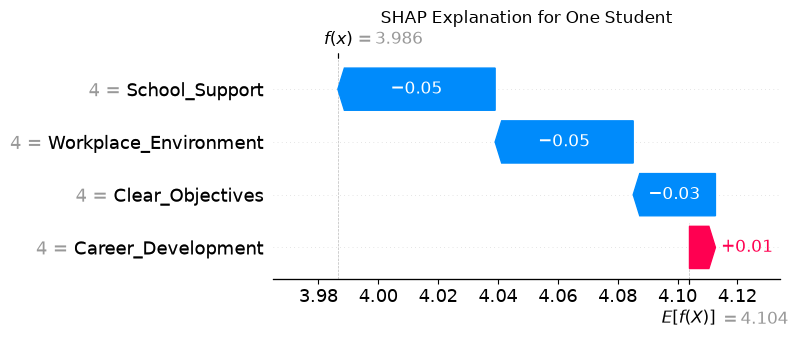

In [96]:
shap.plots.waterfall(
    student_shap,
    max_display=4,
    show=False,
)

plt.title(
    "SHAP Explanation for One Student"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "shap_student_waterfall.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [97]:
absolute_shap_values = np.abs(
    shap_values.values
).flatten()

small_effect_threshold = np.quantile(
    absolute_shap_values,
    0.50,
)

large_effect_threshold = np.quantile(
    absolute_shap_values,
    0.75,
)

print(
    "Small-effect threshold:",
    round(float(small_effect_threshold), 4)
)

print(
    "Large-effect threshold:",
    round(float(large_effect_threshold), 4)
)

Small-effect threshold: 0.0443
Large-effect threshold: 0.0914


In [98]:
def classify_construct_score(score: float) -> str:
    if score < 3.0:
        return "Low"
    elif score < 4.0:
        return "Moderate"
    return "High"

In [99]:
def classify_shap_effect(
    shap_value: float,
    small_threshold: float,
    large_threshold: float,
) -> str:

    magnitude = abs(shap_value)

    if magnitude < small_threshold:
        magnitude_label = "Small"
    elif magnitude < large_threshold:
        magnitude_label = "Moderate"
    else:
        magnitude_label = "Large"

    direction = (
        "Positive"
        if shap_value >= 0
        else "Negative"
    )

    return f"{magnitude_label} {direction}"

In [100]:
def determine_priority(
    score_level: str,
    shap_value: float,
    small_threshold: float,
    large_threshold: float,
) -> str:

    magnitude = abs(shap_value)

    if (
        score_level == "Low"
        and shap_value < 0
        and magnitude >= large_threshold
    ):
        return "High Priority"

    if (
        score_level == "Low"
        and shap_value < 0
    ):
        return "Priority"

    if (
        score_level == "Moderate"
        and shap_value < 0
        and magnitude >= small_threshold
    ):
        return "Moderate Priority"

    if (
        score_level == "High"
        and shap_value > 0
    ):
        return "Strength"

    if (
        score_level == "Moderate"
        and shap_value > 0
    ):
        return "Developing Strength"

    return "Monitor"

In [101]:
recommendation_map = {
    "Clear_Objectives": [
        "Discuss internship goals and expected outcomes with the supervisor.",
        "Break assigned tasks into clear weekly objectives.",
        "Request clarification when tasks or performance expectations are unclear.",
    ],

    "School_Support": [
        "Schedule regular discussions with the academic internship supervisor.",
        "Use institutional career and internship support services.",
        "Request guidance on internship assignments and workplace challenges.",
    ],

    "Workplace_Environment": [
        "Request regular and constructive feedback from the workplace supervisor.",
        "Seek opportunities to collaborate with experienced professionals.",
        "Discuss workplace support needs through the appropriate supervision channel.",
    ],

    "Career_Development": [
        "Participate in challenging projects that build industry-relevant experience.",
        "Seek networking, mentoring, and professional development opportunities.",
        "Document achievements and skills gained during the internship.",
    ],
}

In [102]:
hybrid_analysis = pd.DataFrame({
    "Construct": feature_names,
    "Construct Score": student_data.iloc[0].values,
    "SHAP Contribution": student_shap.values,
})

hybrid_analysis["Score Level"] = (
    hybrid_analysis["Construct Score"]
    .apply(classify_construct_score)
)

hybrid_analysis["SHAP Effect"] = (
    hybrid_analysis["SHAP Contribution"]
    .apply(
        lambda value: classify_shap_effect(
            value,
            small_effect_threshold,
            large_effect_threshold,
        )
    )
)

hybrid_analysis["Priority"] = (
    hybrid_analysis.apply(
        lambda row: determine_priority(
            row["Score Level"],
            row["SHAP Contribution"],
            small_effect_threshold,
            large_effect_threshold,
        ),
        axis=1,
    )
)

hybrid_analysis.round(4)

,Construct,Construct Score,SHAP Contribution,Score Level,SHAP Effect,Priority
0,Clear_Objectives,4.0,-0.0275,High,Small Negative,Monitor
1,School_Support,4.0,-0.0526,High,Moderate Negative,Monitor
2,Workplace_Environment,4.0,-0.0461,High,Moderate Negative,Monitor
3,Career_Development,4.0,0.0087,High,Small Positive,Strength


In [103]:
priority_order = {
    "High Priority": 1,
    "Priority": 2,
    "Moderate Priority": 3,
    "Monitor": 4,
    "Developing Strength": 5,
    "Strength": 6,
}

hybrid_analysis["Priority Rank"] = (
    hybrid_analysis["Priority"]
    .map(priority_order)
)

hybrid_analysis = hybrid_analysis.sort_values(
    [
        "Priority Rank",
        "SHAP Contribution",
    ],
    ascending=[
        True,
        True,
    ],
)

hybrid_analysis.round(4)

,Construct,Construct Score,SHAP Contribution,Score Level,SHAP Effect,Priority,Priority Rank
1,School_Support,4.0,-0.0526,High,Moderate Negative,Monitor,4
2,Workplace_Environment,4.0,-0.0461,High,Moderate Negative,Monitor,4
0,Clear_Objectives,4.0,-0.0275,High,Small Negative,Monitor,4
3,Career_Development,4.0,0.0087,High,Small Positive,Strength,6


In [104]:
def generate_recommendations(
    analysis: pd.DataFrame,
    maximum_constructs: int = 2,
) -> list[dict]:

    improvement_labels = {
        "High Priority",
        "Priority",
        "Moderate Priority",
    }

    priority_rows = analysis[
        analysis["Priority"].isin(
            improvement_labels
        )
    ].head(maximum_constructs)

    output = []

    for _, row in priority_rows.iterrows():
        construct = row["Construct"]

        output.append({
            "Construct": construct,
            "Score": round(
                float(row["Construct Score"]),
                2,
            ),
            "SHAP Contribution": round(
                float(row["SHAP Contribution"]),
                4,
            ),
            "Priority": row["Priority"],
            "Recommendations": recommendation_map[
                construct
            ],
        })

    return output

In [105]:
student_recommendations = generate_recommendations(
    hybrid_analysis
)

student_recommendations

[]

In [106]:
strength_rows = hybrid_analysis[
    hybrid_analysis["Priority"].isin(
        [
            "Strength",
            "Developing Strength",
        ]
    )
].sort_values(
    "SHAP Contribution",
    ascending=False,
)

strength_rows[
    [
        "Construct",
        "Construct Score",
        "SHAP Contribution",
        "Priority",
    ]
].round(4)

,Construct,Construct Score,SHAP Contribution,Priority
3,Career_Development,4.0,0.0087,Strength


Maintenance feedback function

In [107]:
def generate_maintenance_message(strengths):

    if len(strengths) > 0:

        strength_names = [
            item["Construct"].replace("_", " ")
            for item in strengths
        ]

        strengths_text = ", ".join(strength_names)

        return (
            "No priority development area was identified. "
            f"Maintain your current strengths in {strengths_text} "
            "and continue seeking opportunities for professional development."
        )

    return (
        "No priority development area was identified from the current "
        "construct scores and model explanation. Continue maintaining "
        "your current internship performance and seek opportunities "
        "for further professional development."
    )

In [108]:
def create_student_report(
    student_position: int,
) -> dict:

    # ---------------------------------------------------------
    # 1. Validate student position
    # ---------------------------------------------------------
    if not 0 <= student_position < len(X_test):
        raise IndexError(
            "Student position is outside the test dataset."
        )

    # ---------------------------------------------------------
    # 2. Get student input
    # ---------------------------------------------------------
    student_input = X_test.iloc[
        [student_position]
    ]

    # ---------------------------------------------------------
    # 3. Generate prediction
    # ---------------------------------------------------------
    prediction = float(
        final_rf_model.predict(student_input)[0]
    )

    # ---------------------------------------------------------
    # 4. Get actual employability score
    #    (Research evaluation only)
    # ---------------------------------------------------------
    actual = float(
        y_test.iloc[student_position]
    )

    # ---------------------------------------------------------
    # 5. Get SHAP explanation
    # ---------------------------------------------------------
    explanation = shap_values[
        student_position
    ]

    # ---------------------------------------------------------
    # 6. Create construct-level analysis
    # ---------------------------------------------------------
    analysis = pd.DataFrame({
        "Construct": feature_names,

        "Construct Score":
            student_input.iloc[0].values,

        "SHAP Contribution":
            explanation.values,
    })

    # ---------------------------------------------------------
    # 7. Classify construct scores
    # ---------------------------------------------------------
    analysis["Score Level"] = (
        analysis["Construct Score"]
        .apply(classify_construct_score)
    )

    # ---------------------------------------------------------
    # 8. Classify SHAP effect
    # ---------------------------------------------------------
    analysis["SHAP Effect"] = (
        analysis["SHAP Contribution"]
        .apply(
            lambda value: classify_shap_effect(
                value,
                small_effect_threshold,
                large_effect_threshold,
            )
        )
    )

    # ---------------------------------------------------------
    # 9. Determine recommendation priority
    # ---------------------------------------------------------
    analysis["Priority"] = analysis.apply(
        lambda row: determine_priority(
            row["Score Level"],
            row["SHAP Contribution"],
            small_effect_threshold,
            large_effect_threshold,
        ),
        axis=1,
    )

    # ---------------------------------------------------------
    # 10. Priority ranking
    # ---------------------------------------------------------
    analysis["Priority Rank"] = (
        analysis["Priority"]
        .map(priority_order)
    )

    analysis = analysis.sort_values(
        [
            "Priority Rank",
            "SHAP Contribution",
        ],
        ascending=[
            True,
            True,
        ],
    )

    # ---------------------------------------------------------
    # 11. Generate targeted recommendations
    # ---------------------------------------------------------
    recommendations = generate_recommendations(
        analysis
    )

    # ---------------------------------------------------------
    # 12. Identify strengths
    # ---------------------------------------------------------
    strengths = analysis[
        analysis["Priority"].isin(
            [
                "Strength",
                "Developing Strength",
            ]
        )
    ].sort_values(
        "SHAP Contribution",
        ascending=False,
    )

    # ---------------------------------------------------------
    # 13. Convert strengths to records
    # ---------------------------------------------------------
    strength_records = strengths[
        [
            "Construct",
            "Construct Score",
            "SHAP Contribution",
        ]
    ].to_dict("records")

    # ---------------------------------------------------------
    # 14. Generate maintenance message
    #     Only when no improvement recommendation exists
    # ---------------------------------------------------------
    if len(recommendations) == 0:

        maintenance_message = (
            generate_maintenance_message(
                strength_records
            )
        )

    else:

        maintenance_message = None

    # ---------------------------------------------------------
    # 15. Calculate prediction error
    #     Research evaluation only
    # ---------------------------------------------------------
    prediction_error = abs(
        actual - prediction
    )

    # ---------------------------------------------------------
    # 16. Return full student report
    # ---------------------------------------------------------
    return {

        "Student Position":
            student_position,

        "Original Row Index":
            int(
                X_test.index[
                    student_position
                ]
            ),

        "Actual Employability Score":
            round(
                actual,
                3,
            ),

        "Predicted Employability Score":
            round(
                prediction,
                3,
            ),

        "Prediction Error":
            round(
                prediction_error,
                3,
            ),

        "Base Prediction":
            round(
                float(
                    np.asarray(
                        explanation.base_values
                    ).reshape(-1)[0]
                ),
                3,
            ),

        "Strengths":
            strength_records,

        "Recommendations":
            recommendations,

        "Maintenance Message":
            maintenance_message,

        "Full Analysis":
            analysis.drop(
                columns=[
                    "Priority Rank"
                ]
            ).to_dict(
                "records"
            ),
    }

In [109]:
example_report = create_student_report(
    student_position=0
)

example_report

{'Student Position': 0,
 'Original Row Index': 521,
 'Actual Employability Score': 4.0,
 'Predicted Employability Score': 3.986,
 'Prediction Error': 0.014,
 'Base Prediction': 4.104,
 'Strengths': [{'Construct': 'Career_Development',
   'Construct Score': 4.0,
   'SHAP Contribution': 0.008675893821489186}],
 'Recommendations': [],
 'Maintenance Message': 'No priority development area was identified. Maintain your current strengths in Career Development and continue seeking opportunities for professional development.',
 'Full Analysis': [{'Construct': 'School_Support',
   'Construct Score': 4.0,
   'SHAP Contribution': -0.052566090518716004,
   'Score Level': 'High',
   'SHAP Effect': 'Moderate Negative',
   'Priority': 'Monitor'},
  {'Construct': 'Workplace_Environment',
   'Construct Score': 4.0,
   'SHAP Contribution': -0.046142299875814925,
   'Score Level': 'High',
   'SHAP Effect': 'Moderate Negative',
   'Priority': 'Monitor'},
  {'Construct': 'Clear_Objectives',
   'Construct S

In [110]:
print(
    "Predicted Employability Score:",
    example_report[
        "Predicted Employability Score"
    ],
)

print(
    "Actual Employability Score:",
    example_report[
        "Actual Employability Score"
    ],
)

print("\nStrengths:")
for strength in example_report["Strengths"]:
    print(
        "-",
        strength["Construct"],
        "| Score:",
        round(
            float(strength["Construct Score"]),
            2,
        ),
        "| SHAP:",
        round(
            float(strength["SHAP Contribution"]),
            4,
        ),
    )

print("\nPriority Recommendations:")

for item in example_report["Recommendations"]:
    print(
        "\nConstruct:",
        item["Construct"],
    )
    print(
        "Priority:",
        item["Priority"],
    )
    print(
        "Score:",
        item["Score"],
    )
    print(
        "SHAP Contribution:",
        item["SHAP Contribution"],
    )

    for recommendation in item["Recommendations"]:
        print("-", recommendation)

Predicted Employability Score: 3.986
Actual Employability Score: 4.0

Strengths:
- Career_Development | Score: 4.0 | SHAP: 0.0087

Priority Recommendations:


In [111]:
report_file = (
    REPORT_DIR
    / "Example_Student_SHAP_Report.json"
)

with open(
    report_file,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        example_report,
        file,
        indent=4,
        ensure_ascii=False,
        default=float,
    )

print("Student report saved to:")
print(report_file)

Student report saved to:
d:\internship-employability-project\reports\Example_Student_SHAP_Report.json


In [112]:
shap_output = pd.DataFrame(
    shap_values.values,
    columns=[
        f"SHAP_{feature}"
        for feature in feature_names
    ],
    index=X_test.index,
)

shap_output = pd.concat(
    [
        X_test,
        shap_output,
        y_test.rename("Actual_Employability"),
        pd.Series(
            test_predictions,
            index=X_test.index,
            name="Predicted_Employability",
        ),
    ],
    axis=1,
)

shap_output.to_csv(
    REPORT_DIR / "Test_Set_SHAP_Explanations.csv",
    index=True,
)

shap_output.head()

,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,SHAP_Clear_Objectives,SHAP_School_Support,SHAP_Workplace_Environment,SHAP_Career_Development,Actual_Employability,Predicted_Employability
521,4.00,4.0,4.00,4.0,-0.027483,-0.052566,-0.046142,0.008676,4.000,3.986471
737,4.25,4.5,4.25,4.0,0.110513,0.110806,0.004321,0.008538,4.375,4.338164
740,4.00,4.0,4.50,4.0,-0.017534,-0.075912,-0.015183,0.008091,4.000,4.003448
660,4.00,4.0,3.75,4.0,-0.026107,-0.043271,-0.041862,0.009944,4.000,4.002690
411,4.00,4.5,4.00,4.0,-0.038011,0.106238,-0.093309,0.008265,4.500,4.087169


In [113]:
deployment_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)

deployment_model.fit(X, y)

deployment_model_file = (
    MODEL_DIR
    / "final_employability_random_forest.joblib"
)

joblib.dump(
    {
        "model": deployment_model,
        "feature_names": feature_names,
        "target_name": target_name,
        "model_version": "1.0",
        "training_rows": len(X),
        "parameters": deployment_model.get_params(),
        "score_band_rules": {
            "Low": "< 3.0",
            "Moderate": "3.0 to < 4.0",
            "High": ">= 4.0",
        },
        "recommendation_method": (
            "SHAP + construct score hybrid"
        ),
    },
    deployment_model_file,
)

print("Deployment model saved to:")
print(deployment_model_file)

Deployment model saved to:
d:\internship-employability-project\models\final_employability_random_forest.joblib


In [114]:
recommendation_configuration = {
    "feature_names": feature_names,
    "small_shap_threshold": float(
        small_effect_threshold
    ),
    "large_shap_threshold": float(
        large_effect_threshold
    ),
    "score_bands": {
        "low_upper_exclusive": 3.0,
        "moderate_upper_exclusive": 4.0,
    },
    "recommendations": recommendation_map,
}

configuration_file = (
    MODEL_DIR
    / "recommendation_configuration.json"
)

with open(
    configuration_file,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        recommendation_configuration,
        file,
        indent=4,
        ensure_ascii=False,
    )

print("Recommendation configuration saved.")

Recommendation configuration saved.


## SHAP Explainability Method

SHAP was applied to the final Tuned Random Forest model to improve transparency and interpretability.

Global explanations were generated using mean absolute SHAP values to identify the relative importance of Internship Experience constructs across the held-out testing dataset. A SHAP beeswarm plot was used to examine the direction and distribution of feature effects.

Local SHAP explanations were generated for individual students. Each local explanation decomposed the predicted Employability Score into the model's baseline prediction and the positive or negative contribution of each internship construct.

SHAP explanations were calculated for the held-out testing dataset to ensure that the interpretation focused on observations that were not used to fit the research-stage model.

## Hybrid SHAP and Construct-Score Recommendation Method

A hybrid explainable recommendation approach was developed by combining each student's construct scores with local SHAP contributions.

Construct scores were used to indicate the student's current level for each Internship Experience dimension. SHAP values were used to determine whether each construct increased or decreased the student's predicted Employability Score and to measure the relative magnitude of that effect.

Priority development areas were identified when a construct had a relatively low or moderate score together with a meaningful negative SHAP contribution. Strengths were identified when a high construct score made a positive contribution to the prediction.

The recommendation rules used in the prototype are transparent operational rules rather than universally validated thresholds. The action mapping should therefore be reviewed and validated by career advisers, internship coordinators, and domain experts before real-world deployment.

# Research Findings

SHAP analysis demonstrated that the final Tuned Random Forest model was influenced by all four Internship Experience constructs.

The global feature-importance analysis identified **[insert highest-ranked construct]** as the most influential predictor, followed by **[insert second-ranked construct]**. The beeswarm plot showed that higher scores in the leading constructs generally increased predicted Employability Score, while lower scores tended to reduce it.

The individual-level SHAP analysis demonstrated that students with similar predicted Employability Scores could receive those predictions for different reasons. This supports the need for personalized explanations rather than relying only on the overall prediction.

The hybrid recommendation approach successfully combined actual construct scores with model-derived SHAP contributions. This enabled the system to distinguish between personal strengths, factors requiring monitoring, and priority areas for improvement.

The resulting framework extends a standard employability prediction model into an explainable decision-support system that provides prediction, explanation, and personalized recommendations.

## Limitations

SHAP explains the behaviour of the trained model; it does not establish causal relationships between Internship Experience constructs and Employability.

A negative SHAP contribution does not necessarily mean that a construct is universally harmful. It means that, for a specific prediction and relative to the model's expected output, the feature moved the prediction downward.

The construct-score bands and recommendation-priority rules used in the prototype are operational thresholds and require expert validation.

The current model-development dataset is synthetic. Therefore, the model performance, SHAP explanations, and recommendations should not be presented as evidence of real-world population validity until they are evaluated using genuine participant data.

In [115]:
global_importance.round(4)

,Feature,Mean Absolute SHAP,Importance Percentage
0,Clear_Objectives,0.0923,37.2629
1,School_Support,0.0864,34.8713
2,Workplace_Environment,0.0444,17.9363
3,Career_Development,0.0246,9.9295


In [116]:
hybrid_analysis.round(4)

,Construct,Construct Score,SHAP Contribution,Score Level,SHAP Effect,Priority,Priority Rank
1,School_Support,4.0,-0.0526,High,Moderate Negative,Monitor,4
2,Workplace_Environment,4.0,-0.0461,High,Moderate Negative,Monitor,4
0,Clear_Objectives,4.0,-0.0275,High,Small Negative,Monitor,4
3,Career_Development,4.0,0.0087,High,Small Positive,Strength,6


In [117]:
example_report

{'Student Position': 0,
 'Original Row Index': 521,
 'Actual Employability Score': 4.0,
 'Predicted Employability Score': 3.986,
 'Prediction Error': 0.014,
 'Base Prediction': 4.104,
 'Strengths': [{'Construct': 'Career_Development',
   'Construct Score': 4.0,
   'SHAP Contribution': 0.008675893821489186}],
 'Recommendations': [],
 'Maintenance Message': 'No priority development area was identified. Maintain your current strengths in Career Development and continue seeking opportunities for professional development.',
 'Full Analysis': [{'Construct': 'School_Support',
   'Construct Score': 4.0,
   'SHAP Contribution': -0.052566090518716004,
   'Score Level': 'High',
   'SHAP Effect': 'Moderate Negative',
   'Priority': 'Monitor'},
  {'Construct': 'Workplace_Environment',
   'Construct Score': 4.0,
   'SHAP Contribution': -0.046142299875814925,
   'Score Level': 'High',
   'SHAP Effect': 'Moderate Negative',
   'Priority': 'Monitor'},
  {'Construct': 'Clear_Objectives',
   'Construct S

In [118]:
test_positions = [0, 5, 20, 45, 100, 150]

reports = []

for position in test_positions:
    report = create_student_report(position)
    reports.append(report)

    print("=" * 70)
    print("Student Position:", position)
    print(
        "Predicted Score:",
        report["Predicted Employability Score"]
    )
    print("Strengths:", report["Strengths"])
    print("Recommendations:", report["Recommendations"])

Student Position: 0
Predicted Score: 3.986
Strengths: [{'Construct': 'Career_Development', 'Construct Score': 4.0, 'SHAP Contribution': 0.008675893821489186}]
Recommendations: []
Student Position: 5
Predicted Score: 4.338
Strengths: [{'Construct': 'School_Support', 'Construct Score': 4.5, 'SHAP Contribution': 0.1108057948889619}, {'Construct': 'Clear_Objectives', 'Construct Score': 4.25, 'SHAP Contribution': 0.11051299895002298}, {'Construct': 'Career_Development', 'Construct Score': 4.0, 'SHAP Contribution': 0.008538207587410255}, {'Construct': 'Workplace_Environment', 'Construct Score': 4.25, 'SHAP Contribution': 0.004321379264324458}]
Recommendations: []
Student Position: 20
Predicted Score: 3.845
Strengths: [{'Construct': 'Career_Development', 'Construct Score': 4.0, 'SHAP Contribution': 0.012930793394737712}]
Recommendations: [{'Construct': 'Clear_Objectives', 'Score': 3.75, 'SHAP Contribution': -0.1834, 'Priority': 'Moderate Priority', 'Recommendations': ['Discuss internship goal

In [119]:
test_case_data = X_test.copy()

test_case_data["Predicted_Employability"] = (
    final_rf_model.predict(X_test)
)

test_case_data["Actual_Employability"] = y_test.values

test_case_data.sort_values(
    "Predicted_Employability"
).head()

,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Predicted_Employability,Actual_Employability
213,1.25,1.5,2.25,1.0,2.812041,1.000
261,2.50,4.0,1.25,2.0,3.009141,3.375
39,2.75,2.5,3.25,2.0,3.224850,3.000
218,2.50,4.0,4.25,2.0,3.233197,3.000
210,2.00,3.0,3.50,1.0,3.326037,4.625


In [120]:
low_positions = np.argsort(
    final_rf_model.predict(X_test)
)[:3]

In [121]:
high_positions = np.argsort(
    final_rf_model.predict(X_test)
)[-3:]

In [122]:
predictions = final_rf_model.predict(X_test)

middle_target = np.median(predictions)

middle_positions = np.argsort(
    np.abs(predictions - middle_target)
)[:3]

In [123]:
selected_positions = list(
    low_positions
) + list(
    middle_positions
) + list(
    high_positions
)

selected_positions

[np.int64(194),
 np.int64(52),
 np.int64(77),
 np.int64(29),
 np.int64(28),
 np.int64(42),
 np.int64(81),
 np.int64(102),
 np.int64(132)]

In [124]:
case_study_reports = []

for position in selected_positions:
    case_study_reports.append(
        create_student_report(
            int(position)
        )
    )

case_study_reports

[{'Student Position': 194,
  'Original Row Index': 213,
  'Actual Employability Score': 1.0,
  'Predicted Employability Score': 2.812,
  'Prediction Error': 1.812,
  'Base Prediction': 4.104,
  'Strengths': [],
  'Recommendations': [{'Construct': 'Clear_Objectives',
    'Score': 1.25,
    'SHAP Contribution': -0.5616,
    'Priority': 'High Priority',
    'Recommendations': ['Discuss internship goals and expected outcomes with the supervisor.',
     'Break assigned tasks into clear weekly objectives.',
     'Request clarification when tasks or performance expectations are unclear.']},
   {'Construct': 'Career_Development',
    'Score': 1.0,
    'SHAP Contribution': -0.2987,
    'Priority': 'High Priority',
    'Recommendations': ['Participate in challenging projects that build industry-relevant experience.',
     'Seek networking, mentoring, and professional development opportunities.',
     'Document achievements and skills gained during the internship.']}],
  'Maintenance Message': No

this is for analysisi part


In [125]:
print("Low cases:", low_positions)
print("Middle cases:", middle_positions)
print("High cases:", high_positions)
print("All selected positions:", selected_positions)

Low cases: [194  52  77]
Middle cases: [29 28 42]
High cases: [ 81 102 132]
All selected positions: [np.int64(194), np.int64(52), np.int64(77), np.int64(29), np.int64(28), np.int64(42), np.int64(81), np.int64(102), np.int64(132)]


In [126]:
case_summary = []

for position in selected_positions:
    report = create_student_report(int(position))

    priority_constructs = [
        item["Construct"]
        for item in report["Recommendations"]
    ]

    strength_constructs = [
        item["Construct"]
        for item in report["Strengths"]
    ]

    case_summary.append({
        "Student Position": position,
        "Actual Score": report["Actual Employability Score"],
        "Predicted Score": report["Predicted Employability Score"],
        "Strengths": ", ".join(strength_constructs),
        "Priority Areas": ", ".join(priority_constructs),
        "Recommendation Count": len(report["Recommendations"])
    })

case_summary_df = pd.DataFrame(case_summary)

case_summary_df

,Student Position,Actual Score,Predicted Score,Strengths,Priority Areas,Recommendation Count
0,194,1.000,2.812,,"Clear_Objectives, Career_Development",2
1,52,3.375,3.009,,"Clear_Objectives, Career_Development",2
2,77,3.000,3.225,,"Clear_Objectives, Career_Development",2
3,29,4.000,4.056,"Workplace_Environment, Career_Development",,0
4,28,4.250,4.056,"Workplace_Environment, Career_Development",,0
5,42,4.125,4.056,"Workplace_Environment, Career_Development",,0
6,81,5.000,4.675,"Workplace_Environment, School_Support, Clear_O...",,0
7,102,4.875,4.685,"Workplace_Environment, School_Support, Clear_O...",,0
8,132,5.000,4.685,"Workplace_Environment, School_Support, Clear_O...",,0


In [127]:
low_case_report = create_student_report(
    int(low_positions[0])
)

low_case_report

{'Student Position': 194,
 'Original Row Index': 213,
 'Actual Employability Score': 1.0,
 'Predicted Employability Score': 2.812,
 'Prediction Error': 1.812,
 'Base Prediction': 4.104,
 'Strengths': [],
 'Recommendations': [{'Construct': 'Clear_Objectives',
   'Score': 1.25,
   'SHAP Contribution': -0.5616,
   'Priority': 'High Priority',
   'Recommendations': ['Discuss internship goals and expected outcomes with the supervisor.',
    'Break assigned tasks into clear weekly objectives.',
    'Request clarification when tasks or performance expectations are unclear.']},
  {'Construct': 'Career_Development',
   'Score': 1.0,
   'SHAP Contribution': -0.2987,
   'Priority': 'High Priority',
   'Recommendations': ['Participate in challenging projects that build industry-relevant experience.',
    'Seek networking, mentoring, and professional development opportunities.',
    'Document achievements and skills gained during the internship.']}],
 'Maintenance Message': None,
 'Full Analysis': 

Full report for one middle case

In [128]:
middle_case_report = create_student_report(
    int(middle_positions[0])
)

middle_case_report

{'Student Position': 29,
 'Original Row Index': 947,
 'Actual Employability Score': 4.0,
 'Predicted Employability Score': 4.056,
 'Prediction Error': 0.056,
 'Base Prediction': 4.104,
 'Strengths': [{'Construct': 'Workplace_Environment',
   'Construct Score': 4.25,
   'SHAP Contribution': 0.029009497569110084},
  {'Construct': 'Career_Development',
   'Construct Score': 4.0,
   'SHAP Contribution': 0.009304851342056088}],
 'Recommendations': [],
 'Maintenance Message': 'No priority development area was identified. Maintain your current strengths in Workplace Environment, Career Development and continue seeking opportunities for professional development.',
 'Full Analysis': [{'Construct': 'School_Support',
   'Construct Score': 4.0,
   'SHAP Contribution': -0.07006833315503944,
   'Score Level': 'High',
   'SHAP Effect': 'Moderate Negative',
   'Priority': 'Monitor'},
  {'Construct': 'Clear_Objectives',
   'Construct Score': 4.0,
   'SHAP Contribution': -0.016426261240859434,
   'Score

Full report for one high case

In [129]:
high_case_report = create_student_report(
    int(high_positions[-1])
)

high_case_report

{'Student Position': 132,
 'Original Row Index': 265,
 'Actual Employability Score': 5.0,
 'Predicted Employability Score': 4.685,
 'Prediction Error': 0.315,
 'Base Prediction': 4.104,
 'Strengths': [{'Construct': 'Workplace_Environment',
   'Construct Score': 5.0,
   'SHAP Contribution': 0.20081250810848242},
  {'Construct': 'School_Support',
   'Construct Score': 5.0,
   'SHAP Contribution': 0.17816685477387245},
  {'Construct': 'Clear_Objectives',
   'Construct Score': 5.0,
   'SHAP Contribution': 0.1411262357173536},
  {'Construct': 'Career_Development',
   'Construct Score': 5.0,
   'SHAP Contribution': 0.06117125075893823}],
 'Recommendations': [],
 'Maintenance Message': 'No priority development area was identified. Maintain your current strengths in Workplace Environment, School Support, Clear Objectives, Career Development and continue seeking opportunities for professional development.',
 'Full Analysis': [{'Construct': 'Career_Development',
   'Construct Score': 5.0,
   'SH

Hybrid-analysis tables for those three cases

In [130]:
def get_hybrid_analysis(student_position):

    student_input = X_test.iloc[
        [student_position]
    ]

    explanation = shap_values[
        student_position
    ]

    analysis = pd.DataFrame({
        "Construct": feature_names,
        "Construct Score": (
            student_input.iloc[0].values
        ),
        "SHAP Contribution": explanation.values
    })

    analysis["Score Level"] = (
        analysis["Construct Score"]
        .apply(classify_construct_score)
    )

    analysis["SHAP Effect"] = (
        analysis["SHAP Contribution"]
        .apply(
            lambda value: classify_shap_effect(
                value,
                small_effect_threshold,
                large_effect_threshold
            )
        )
    )

    analysis["Priority"] = analysis.apply(
        lambda row: determine_priority(
            row["Score Level"],
            row["SHAP Contribution"],
            small_effect_threshold,
            large_effect_threshold
        ),
        axis=1
    )

    return analysis

In [131]:
print("LOW CASE")
display(
    get_hybrid_analysis(
        int(low_positions[0])
    )
)

print("MIDDLE CASE")
display(
    get_hybrid_analysis(
        int(middle_positions[0])
    )
)

print("HIGH CASE")
display(
    get_hybrid_analysis(
        int(high_positions[-1])
    )
)

LOW CASE


,Construct,Construct Score,SHAP Contribution,Score Level,SHAP Effect,Priority
0,Clear_Objectives,1.25,-0.561568,Low,Large Negative,High Priority
1,School_Support,1.50,-0.289670,Low,Large Negative,High Priority
2,Workplace_Environment,2.25,-0.141964,Low,Large Negative,High Priority
3,Career_Development,1.00,-0.298743,Low,Large Negative,High Priority


MIDDLE CASE


,Construct,Construct Score,SHAP Contribution,Score Level,SHAP Effect,Priority
0,Clear_Objectives,4.00,-0.016426,High,Small Negative,Monitor
1,School_Support,4.00,-0.070068,High,Moderate Negative,Monitor
2,Workplace_Environment,4.25,0.029009,High,Small Positive,Strength
3,Career_Development,4.00,0.009305,High,Small Positive,Strength


HIGH CASE


,Construct,Construct Score,SHAP Contribution,Score Level,SHAP Effect,Priority
0,Clear_Objectives,5.0,0.141126,High,Large Positive,Strength
1,School_Support,5.0,0.178167,High,Large Positive,Strength
2,Workplace_Environment,5.0,0.200813,High,Large Positive,Strength
3,Career_Development,5.0,0.061171,High,Moderate Positive,Strength


Recommendation coverage check

In [132]:
all_test_reports = [
    create_student_report(i)
    for i in range(len(X_test))
]

students_with_recommendations = sum(
    len(report["Recommendations"]) > 0
    for report in all_test_reports
)

students_without_recommendations = (
    len(all_test_reports)
    - students_with_recommendations
)

print(
    "Students with recommendations:",
    students_with_recommendations
)

print(
    "Students without recommendations:",
    students_without_recommendations
)

Students with recommendations: 34
Students without recommendations: 166


Check recommendation coverage by predicted performance

In [133]:
evaluation_rows = []

for i in range(len(X_test)):
    report = create_student_report(i)

    evaluation_rows.append({
        "Student Position": i,
        "Predicted Score":
            report["Predicted Employability Score"],
        "Actual Score":
            report["Actual Employability Score"],
        "Recommendation Count":
            len(report["Recommendations"])
    })

recommendation_eval = pd.DataFrame(
    evaluation_rows
)

recommendation_eval.head()

,Student Position,Predicted Score,Actual Score,Recommendation Count
0,0,3.986,4.000,0
1,1,4.338,4.375,0
2,2,4.003,4.000,0
3,3,4.003,4.000,0
4,4,4.087,4.500,0


In [134]:
def prediction_group(score):
    if score < 3.0:
        return "Lower"
    elif score < 4.0:
        return "Middle"
    else:
        return "Higher"

recommendation_eval["Prediction Group"] = (
    recommendation_eval["Predicted Score"]
    .apply(prediction_group)
)

In [135]:
coverage_by_group = (
    recommendation_eval
    .groupby("Prediction Group")
    .agg(
        Students=("Student Position", "count"),
        Students_With_Recommendations=(
            "Recommendation Count",
            lambda x: (x > 0).sum()
        ),
        Average_Recommendations=(
            "Recommendation Count",
            "mean"
        )
    )
)

coverage_by_group

,Students,Students_With_Recommendations,Average_Recommendations
Prediction Group,,,
Higher,133,11,0.105263
Lower,1,1,2.000000
Middle,66,22,0.575758


In [136]:
low_without_recommendations = (
    recommendation_eval[
        (recommendation_eval["Predicted Score"] < 3.0)
        &
        (recommendation_eval["Recommendation Count"] == 0)
    ]
)

low_without_recommendations

,Student Position,Predicted Score,Actual Score,Recommendation Count,Prediction Group


User-friendly report display function

In [137]:
def display_student_report(report):

    print("=" * 70)
    print("PERSONALIZED EMPLOYABILITY REPORT")
    print("=" * 70)

    print(
        "\nPredicted Employability Score:",
        report["Predicted Employability Score"]
    )

    print(
        "Actual Employability Score:",
        report["Actual Employability Score"]
    )

    print("\nSTRENGTHS")

    if report["Strengths"]:
        for item in report["Strengths"]:
            print(
                f"- {item['Construct'].replace('_', ' ')} "
                f"(Score: {item['Construct Score']:.2f})"
            )
    else:
        print("- No major strength identified.")

    print("\nDEVELOPMENT RECOMMENDATIONS")

    if report["Recommendations"]:

        for item in report["Recommendations"]:

            print(
                f"\n{item['Construct'].replace('_', ' ')}"
            )

            print(
                "Priority:",
                item["Priority"]
            )

            for recommendation in item[
                "Recommendations"
            ]:
                print(
                    "-",
                    recommendation
                )

    else:

        print(
            report["Maintenance Message"]
        )

    print("\n" + "=" * 70)

In [138]:
display_student_report(
    create_student_report(
        int(low_positions[0])
    )
)

PERSONALIZED EMPLOYABILITY REPORT

Predicted Employability Score: 2.812
Actual Employability Score: 1.0

STRENGTHS
- No major strength identified.

DEVELOPMENT RECOMMENDATIONS

Clear Objectives
Priority: High Priority
- Discuss internship goals and expected outcomes with the supervisor.
- Break assigned tasks into clear weekly objectives.
- Request clarification when tasks or performance expectations are unclear.

Career Development
Priority: High Priority
- Participate in challenging projects that build industry-relevant experience.
- Seek networking, mentoring, and professional development opportunities.
- Document achievements and skills gained during the internship.



In [139]:
display_student_report(
    create_student_report(
        int(middle_positions[0])
    )
)

PERSONALIZED EMPLOYABILITY REPORT

Predicted Employability Score: 4.056
Actual Employability Score: 4.0

STRENGTHS
- Workplace Environment (Score: 4.25)
- Career Development (Score: 4.00)

DEVELOPMENT RECOMMENDATIONS
No priority development area was identified. Maintain your current strengths in Workplace Environment, Career Development and continue seeking opportunities for professional development.



In [140]:
display_student_report(
    create_student_report(
        int(high_positions[-1])
    )
)

PERSONALIZED EMPLOYABILITY REPORT

Predicted Employability Score: 4.685
Actual Employability Score: 5.0

STRENGTHS
- Workplace Environment (Score: 5.00)
- School Support (Score: 5.00)
- Clear Objectives (Score: 5.00)
- Career Development (Score: 5.00)

DEVELOPMENT RECOMMENDATIONS
No priority development area was identified. Maintain your current strengths in Workplace Environment, School Support, Clear Objectives, Career Development and continue seeking opportunities for professional development.



In [141]:
all_test_reports = [
    create_student_report(i)
    for i in range(len(X_test))
]

students_with_recommendations = sum(
    len(report["Recommendations"]) > 0
    for report in all_test_reports
)

students_without_recommendations = (
    len(all_test_reports)
    - students_with_recommendations
)

print(
    "Students with recommendations:",
    students_with_recommendations
)

print(
    "Students without recommendations:",
    students_without_recommendations
)

Students with recommendations: 34
Students without recommendations: 166


Recommendation coverage by predicted group

In [142]:
evaluation_rows = []

for i in range(len(X_test)):
    report = create_student_report(i)

    evaluation_rows.append({
        "Student Position": i,
        "Predicted Score":
            report["Predicted Employability Score"],
        "Actual Score":
            report["Actual Employability Score"],
        "Recommendation Count":
            len(report["Recommendations"])
    })

recommendation_eval = pd.DataFrame(
    evaluation_rows
)

recommendation_eval.head()

,Student Position,Predicted Score,Actual Score,Recommendation Count
0,0,3.986,4.000,0
1,1,4.338,4.375,0
2,2,4.003,4.000,0
3,3,4.003,4.000,0
4,4,4.087,4.500,0


In [143]:
def prediction_group(score):
    if score < 3.0:
        return "Lower"
    elif score < 4.0:
        return "Middle"
    else:
        return "Higher"

recommendation_eval["Prediction Group"] = (
    recommendation_eval["Predicted Score"]
    .apply(prediction_group)
)

In [144]:
coverage_by_group = (
    recommendation_eval
    .groupby("Prediction Group")
    .agg(
        Students=("Student Position", "count"),

        Students_With_Recommendations=(
            "Recommendation Count",
            lambda x: (x > 0).sum()
        ),

        Average_Recommendations=(
            "Recommendation Count",
            "mean"
        )
    )
)

coverage_by_group

,Students,Students_With_Recommendations,Average_Recommendations
Prediction Group,,,
Higher,133,11,0.105263
Lower,1,1,2.000000
Middle,66,22,0.575758


In [145]:
low_without_recommendations = (
    recommendation_eval[
        (recommendation_eval["Predicted Score"] < 3.0)
        &
        (recommendation_eval["Recommendation Count"] == 0)
    ]
)

low_without_recommendations

,Student Position,Predicted Score,Actual Score,Recommendation Count,Prediction Group


## Multiple-Case Validation Findings

The hybrid SHAP and construct-score recommendation logic was evaluated across the held-out test dataset.

Recommendation coverage varied according to predicted employability level. The single case in the lower prediction group received targeted development recommendations. Among students in the middle prediction group, 22 of 66 received recommendations, while only 11 of 133 students in the higher prediction group received targeted recommendations.

Importantly, no student with a predicted Employability Score below 3.0 was left without a development recommendation. This indicates that the hybrid logic successfully identified priority development areas among lower-performing cases while remaining relatively conservative for higher-performing students.

Higher-performing students without identified priority areas received maintenance-oriented feedback rather than unnecessary development recommendations.

These findings provide preliminary validation that the hybrid SHAP and construct-score logic behaves consistently across different prediction profiles.